# 🎬 Word2Vec

### 1. Importamos la clase

In [2]:
%pip install gensim nltk seaborn scikit-learn matplotlib pandas
import sys
sys.path.append("..")

from src.embeddings_w2v import Clase_W2V

  Using cached gensim-4.4.0-cp313-cp313-win_amd64.whl.metadata (8.6 kB)
Using cached gensim-4.4.0-cp313-cp313-win_amd64.whl (24.4 MB)

   ---------------------------------------- 0/2 [smart_open]
   -------------------- ------------------- 1/2 [gensim]
   -------------------- ------------------- 1/2 [gensim]
   -------------------- ------------------- 1/2 [gensim]
   -------------------- ------------------- 1/2 [gensim]
   -------------------- ------------------- 1/2 [gensim]
   -------------------- ------------------- 1/2 [gensim]
   -------------------- ------------------- 1/2 [gensim]
   -------------------- ------------------- 1/2 [gensim]
   -------------------- ------------------- 1/2 [gensim]
   -------------------- ------------------- 1/2 [gensim]
   ---------------------------------------- 2/2 [gensim]

Note: you may need to restart the kernel to use updated packages.


### 🧠 Entrenamiento de Word2Vec

In [13]:
w2v = Clase_W2V("../data/processed/movies_unificado.csv")
w2v.cargar_y_limpiar()
w2v.entrenar()
w2v.guardar_kv("../data/results/word2vec_peliculas.kv")
w2v.exportar_embeddings("../data/results/embeddings.word2vec_avg.csv")

Reseñas: 6672 | Tokens totales: 71750


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Word2Vec entrenado: 2534 palabras x 100 dimensiones
Vectores guardados en: ../data/results/word2vec_peliculas.kv
  Para cargarlos: KeyedVectors.load('../data/results/word2vec_peliculas.kv')

Embeddings guardados en: ../data/results/embeddings.word2vec_avg.csv (6672 reseñas, 100 dims)
  Reseñas sin vector (ninguna palabra en el vocabulario): 31


**Interpretación:** Se entrenó Word2Vec con 6.672 reseñas, que después de la limpieza quedaron en unas 71.750 palabras. El modelo aprendió 2.534 palabras distintas, cada una representada como un vector de 100 números, de modo que las palabras usadas en contextos parecidos quedan con vectores parecidos. Luego cada reseña se resumió en un solo vector de 100 números, calculado como el promedio de los vectores de sus palabras. En 31 reseñas ninguna palabra estaba en el vocabulario, por lo que su vector quedó en ceros.

### 📊 Análisis

In [ ]:
# Vecinos semánticos
w2v.vecinos()  


=== VECINOS SEMÁNTICOS ===

'guion':
   cinemanía          0.715
   inesperada         0.689
   limitaciones       0.684
   weekly             0.684
   relativamente      0.682
   rachel             0.681
   bloody             0.679
   entertainment      0.678

'actuación':
   portman            0.583
   cinematografía     0.535
   patrick            0.513
   casting            0.513
   carrey             0.509
   paisajes           0.503
   rendimiento        0.499
   categoría          0.499

'aburrida':
   coherente          0.615
   post               0.586
   príncipe           0.577
   locos              0.554
   lobos              0.553
   defore             0.535
   cursi              0.526
   tortura            0.518

'obra maestra':
   desnudo            0.744
   kurosawa           0.705
   discurso           0.687
   audaz              0.628
   retrospectiva      0.627
   toy                0.621
   grand              0.620
   creada             0.609

'predecible':
   prín

**Interpretación:** Para la palabra “guion” se acerca a cinemanía (0.715) y “actuación” a portman (0.583), que son del mundo del cine, “aburrida” se acerca a coherente (0.615), que son lo contrario, “obra maestra” a desnudo (0.744) y “predecible” a príncipe (0.691), pero como podemos ver solo dos de los cinco vecinos principales pertenecen al campo cinematográfico, y las similitudes son moderadas (0.58 a 0.74), no altas.

In [ ]:
# Campos Semánticos
w2v.campos_semanticos()


=== CAMPOS SEMÁNTICOS ===

[Guion y trama]
   guion          -> cinemanía, inesperada, limitaciones, weekly, relativamente, rachel
   historia       -> contada, película, desarrolla, seres, sentimiento, potente
   trama          -> parcela, paisajes, agujeros, casting, sencilla, genérica
   argumento      -> morales, menor, sucede, rato, valor, fernando
   final          -> barcos, medio, inesperado, puesta, capítulo, tercer

[Actuación y reparto]
   actuación      -> portman, cinematografía, patrick, casting, carrey, paisajes
   actor          -> ley, ford, escritor, mete, aniston, edgar
   actriz         -> portman, filmado, actúa, sandra, escuches, fenomenal
   reparto        -> estelar, doctor, excepcional, rendimiento, talentoso, jessica
   personajes     -> presente, paisajes, fuertes, repente, principales, sencilla

[Aspectos técnicos]
   fotografía     -> paisajes, fenomenal, importancia, magistral, excelentes, realizada
   música         -> baile, caída, banda, regalo, sonora

**Interpretación:** Como podemos observar, en cada campo semántico algunas palabras quedaron bien relacionadas y otras no. En guion y trama, ‘historia’ quedó cerca de ‘contada’ y ‘desarrolla’, pero ‘guion’ quedó cerca de palabras sin relación como ‘weekly’ y ‘rachel’. En actuación y reparto, ‘reparto’ quedó cerca de ‘estelar’ y ‘talentoso’, pero ‘actor’ y ‘actriz’ se llenaron de nombres propios. Los aspectos técnicos fueron los mejor agrupados: ‘efectos’ quedó cerca de ‘especiales’ y ‘visuales’, y ‘banda’ cerca de ‘sonora’. En ritmo y duración, ‘duración’ quedó cerca de ‘larga’ y ‘horas’, y en emociones, ‘llorar’ quedó cerca de ‘reír’.

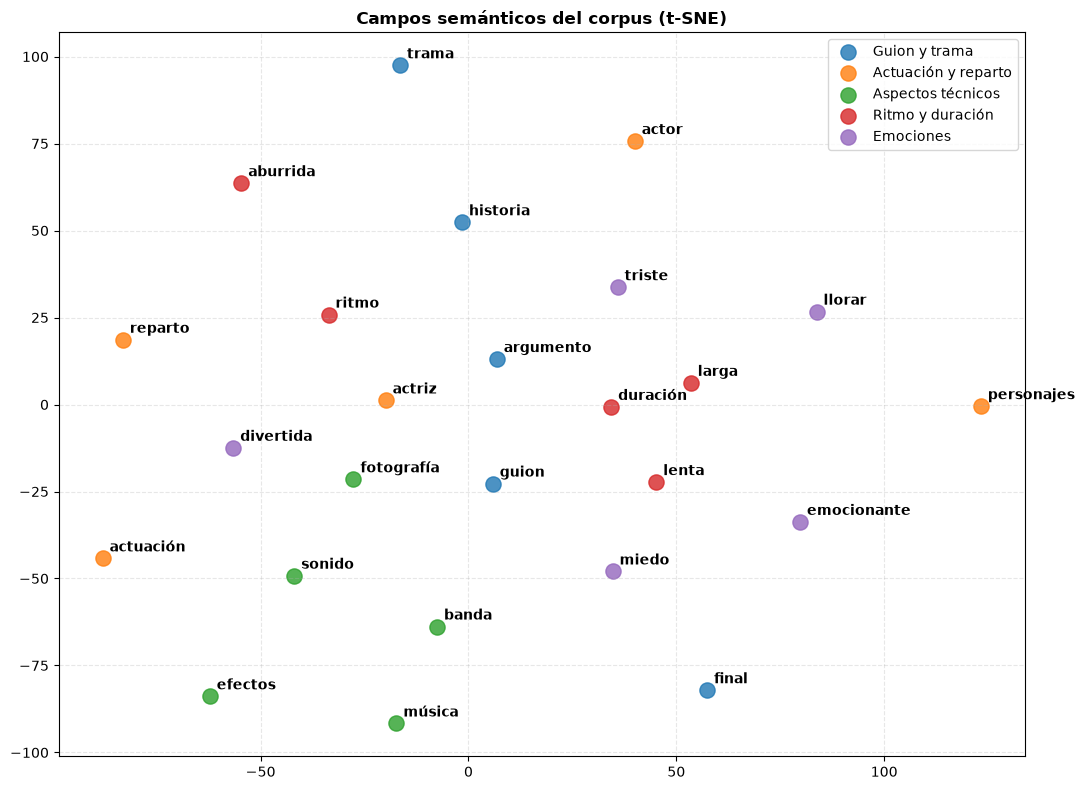

In [7]:
# Gráfico de t-SNE
w2v.graficar_campos() 

**Interpretación:** El gráfico t-SNE muestra que el modelo agrupa con gran precisión los conceptos de aspectos técnicos, mientras que los términos de guion y actuación aparecen mucho más dispersos y mezclados.

In [8]:
# Analogías
w2v.analogias()


=== ANALOGÍAS VECTORIALES ===

actor - hombre + mujer
   charlize           0.546
   creado             0.513
   mencionar          0.498
   theron             0.496
   daniel             0.492

terror - miedo + risa
   carente            0.527
   inspirada          0.517
   vulgar             0.509
   tonta              0.478
   barato             0.477

película - cine + televisión
   creación           0.539
   anuncios           0.536
   programas          0.506
   domingo            0.502
   crees              0.491

excelente - buena + mala
   valor              0.409
   dando              0.409
   ejemplo            0.407
   falta              0.398
   amy                0.384

director - actor + actriz
   elementos          0.490
   coherente          0.489
   keanu              0.488
   increíblemente     0.482
   creativa           0.478

aburrida - lenta + emocionante
   genérica           0.439
   efecto             0.430
   elementos          0.415
   disfrutando        0

**Interpretación:** Podemos observar que el modelo captura bien las asociaciones temáticas del corpus, por ejemplo, al buscar el equivalente femenino de actor, devuelve nombres como 'charlize' y 'theron', y al trasladar película al ámbito de la televisión, identifica conceptos propios como 'anuncios' y 'programas'. Sin embargo, en analogías como excelente - buena + mala pierde precisión y arroja palabras genéricas con menor similitud.

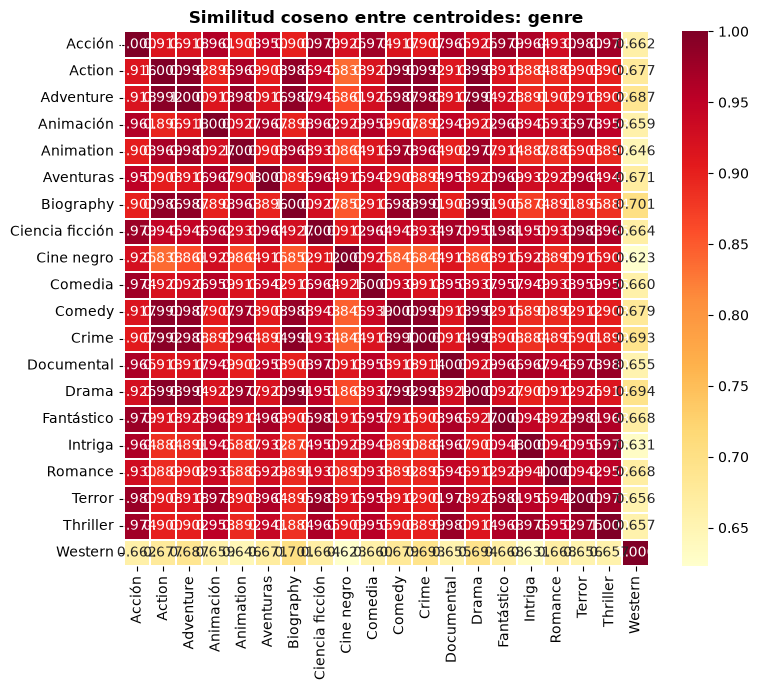

In [10]:
# Gráfico - Similitud entre categorias
w2v.graficar_similitud("genre") 

**Interpretación:** En este gráfico de similitud entre géneros, el resultado más cercano se observa entre la mayoría de las categorías como Drama y Aventura o Comedia y Terror, que presentan valores alto de 0.99 debido al uso de un vocabulario general que pueden compartir, por otro lado, el resultado más alejado es el **Western**, que muestra los valores más bajos de 0.65, indicando que posee un vocabulario más diferenciado respecto al resto.

In [11]:
# Vocabulario Exclusivo
w2v.vocabulario_exclusivo("genre")


=== VOCABULARIO CARACTERÍSTICO POR GENRE ===

[Acción]  diario, interpretaciones, país, interés, giros, premisa, ofrece, variety, acción, espectadores

[Action]  salió, podía, leer, dvd, leí, creer, iba, oído, mira, acuerdo

[Adventure]  leí, leer, salió, libros, leído, quería, acuerdo, decepcionado, oído, acabo

[Animación]  animación, encantador, maravilloso, cinematográfica, lucha, hadas, rogerebert, reporter, cuento, empire

[Animation]  disney, animada, encantadora, pixar, adultos, genial, película, favorita, quería, palabra

[Aventuras]  naturaleza, encantador, cuento, rogerebert, hadas, larga, com, hollywood, vista, alma

[Biography]  leer, dvd, debo, siento, acuerdo, creer, quiero, oscar, acabo, leí

[Ciencia ficción]  reporter, premisa, encima, política, new, ideas, entretenida, suficientemente, género, naturaleza

[Cine negro]  cine, diario, negro, país, género, estilo, clásico, emoción, cinematográfico, viejo

[Comedia]  comedia, romance, diario, lleva, romántica, país, vio

{'Acción': ['diario',
  'interpretaciones',
  'país',
  'interés',
  'giros',
  'premisa',
  'ofrece',
  'variety',
  'acción',
  'espectadores'],
 'Action': ['salió',
  'podía',
  'leer',
  'dvd',
  'leí',
  'creer',
  'iba',
  'oído',
  'mira',
  'acuerdo'],
 'Adventure': ['leí',
  'leer',
  'salió',
  'libros',
  'leído',
  'quería',
  'acuerdo',
  'decepcionado',
  'oído',
  'acabo'],
 'Animación': ['animación',
  'encantador',
  'maravilloso',
  'cinematográfica',
  'lucha',
  'hadas',
  'rogerebert',
  'reporter',
  'cuento',
  'empire'],
 'Animation': ['disney',
  'animada',
  'encantadora',
  'pixar',
  'adultos',
  'genial',
  'película',
  'favorita',
  'quería',
  'palabra'],
 'Aventuras': ['naturaleza',
  'encantador',
  'cuento',
  'rogerebert',
  'hadas',
  'larga',
  'com',
  'hollywood',
  'vista',
  'alma'],
 'Biography': ['leer',
  'dvd',
  'debo',
  'siento',
  'acuerdo',
  'creer',
  'quiero',
  'oscar',
  'acabo',
  'leí'],
 'Ciencia ficción': ['reporter',
  'premi

**Interpretación:** Como podemos observar nn esta lista de vocabulario característico por género, se observa una clara diferencia según el idioma de la etiqueta: los géneros en **español** reflejan términos propios de críticas profesionales (como *guardian*, *variety* o *rogerebert* en *Terror*, *Intriga* y *Documental*), mientras que los etiquetados en **inglés** (*Action*, *Adventure*, *Drama*) muestran un lenguaje más coloquial e informal de usuarios hablando sobre su experiencia (*dvd*, *leí*, *creer*, *acabo*). Asimismo, destacan categorías muy bien definidas por su temática específica como *Animation* (*disney*, *pixar*) o *Animación* (*hadas*, *cuento*), frente al *Western*, cuyo vocabulario más narrativo y aislado (*hombre*, *joven*, *pasado*) explica por qué aparecía como el género más alejado en el gráfico de similitud anterior.

In [12]:
# Calcos
w2v.calcos()


=== POSIBLES CALCOS DE TRADUCCIÓN ===
palabra            traducido      nativo   vecinos
remolque                1.90        0.00   ansioso, leas, emocionado, leí, lea
complot                 1.55        0.00   supongo, pop, crea, enorme, pelea
escenario               1.90        3.64   paisajes, rodríguez, hermosos, interpretada, romeo
caracteres              0.69        0.00   (fuera del vocabulario)
realmente              32.42        8.00   siento, odiar, escuches, caliente, quería
definitivamente         7.41        2.91   reloj, recomiendo, chick, flick, verdaderos
ciertamente             3.10        0.73   reloj, cualidades, admito, cabello, intenciones
actualmente             0.34        0.00   (fuera del vocabulario)
eventualmente           0.69        0.00   (fuera del vocabulario)
teatro                  6.55        0.00   odiaba, aliento, silent, alegro, haberlo
teatros                 1.55        0.00   recientemente, compré, quedé, mañana, usuarios
gráficos              

**Interpretación:** Esta tabla evidencia la presencia de traducciones automáticas literales (calcos del inglés) al comparar la frecuencia de ciertas palabras en reseñas traducidas frente a las nativas en español. Por un lado, aparecen errores literales ausentes en textos nativos 0.00, como traducir trailer por "remolque" 1.90, plot por "complot" 1.55, por otro lado, se notan adverbios terminados en -mente típicos del inglés, como "realmente" (really), que es cuatro veces más frecuente en textos traducidos 32.42 que en nativos 8.00.